# 05 · Agricultural warehouse scenario simulation

**Goal:** Re-solve the *same Linear Programming model* implemented in `04_agriculture_optimization.ipynb` under controlled what-if assumptions. Compare optimal holding/selling decisions, economic benefit, warehouse utilization, shadow prices, and binding constraints.

**Input:** `outputs/agriculture_optimization/allocation_2025.csv`, `model_assumptions.json`, `optimization_summary.json` created by notebook 04. **Run notebook 04 first.** Source stock volumes are derived from agricultural form 50-сг for 2025; future prices, storage fees, reserve fractions, capacity and crop-space multipliers are *illustrative assumptions*, **not historical measurements or forecasts**.

**Important:** Results are hypothetical decision-support exercises, not real enterprise recommendations. No distribution routes, individual warehouse locations, transport costs, or seasonal time steps are available in these inputs.

## 0 · Libraries and file locations

In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.0,<3" "scipy>=1.11,<2" "matplotlib>=3.7,<4"


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
SOURCE = ROOT / "outputs" / "agriculture_optimization"
OUT = ROOT / "outputs" / "agriculture_scenarios"
OUT.mkdir(parents=True, exist_ok=True)
required = [SOURCE / "allocation_2025.csv", SOURCE / "model_assumptions.json", SOURCE / "optimization_summary.json"]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Run notebook 04 locally first. Missing: " + ", ".join(missing))

allocation = pd.read_csv(SOURCE / "allocation_2025.csv", encoding="utf-8-sig")
assumptions = json.loads((SOURCE / "model_assumptions.json").read_text(encoding="utf-8"))
previous_summary = json.loads((SOURCE / "optimization_summary.json").read_text(encoding="utf-8"))
assert assumptions.get("assumptions_are_illustrative") is True
print("Source:", SOURCE)
print("Destination:", OUT)
display(allocation[["crop","available_tonnes","sell_now_price_uah_per_t","later_price_change_pct","holding_cost_uah_per_t","space_units_per_tonne"]])

Source: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/outputs/agriculture_optimization
Destination: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/outputs/agriculture_scenarios


,crop,available_tonnes,sell_now_price_uah_per_t,later_price_change_pct,holding_cost_uah_per_t,space_units_per_tonne
0,barley,2524.6,6500,7,300,1.00
1,maize,13297.2,7200,6,310,1.05
2,rapeseed,7851.6,17500,5,480,0.95
3,soybeans,3171.4,14500,10,420,1.00
4,sunflower,1393.3,16500,8,440,0.95
5,wheat,9161.4,7700,8,320,1.00


## 1 · Baseline validation

Construct the data frame *from the recorded model assumptions* and stock availability in the exported allocation. This avoids relying on variables in notebook 04's kernel. Check that the baseline solution reproduces notebook 04 (up to numerical tolerances).

In [3]:
CROPS = allocation["crop"].astype(str).tolist()
if allocation.crop.duplicated().any():
    raise ValueError("Duplicate crop names in 04 allocation")
if set(CROPS) != set(assumptions["crop_assumptions"]):
    raise ValueError("Assumptions and allocation have different crops")
if len(allocation) != 6:
    print("NOTE: data contains",len(allocation),"crops, not the original six.")

base = allocation[["crop","available_tonnes"]].copy()
for col in ["sell_now_price_uah_per_t", "later_price_change_pct", "holding_cost_uah_per_t", "space_units_per_tonne"]:
    base[col] = base.crop.map(lambda crop: assumptions["crop_assumptions"][crop][col]).astype(float)
BASE_RESERVE = float(assumptions["minimum_reserve_fraction"])
BASE_CAPACITY_SHARE = float(assumptions["capacity_share_of_full_stock_space"])
BASE_FULL_SPACE = float((base.available_tonnes * base.space_units_per_tonne).sum())
BASE_CAPACITY = BASE_CAPACITY_SHARE * BASE_FULL_SPACE
assert 0 <= BASE_RESERVE <= 1
assert BASE_CAPACITY_SHARE > 0
assert np.isfinite(base.select_dtypes(include="number").to_numpy()).all()
assert (base.available_tonnes >= 0).all() and (base.space_units_per_tonne > 0).all()
print(f"Recorded reserve = {BASE_RESERVE:.0%}, capacity = {BASE_CAPACITY:,.2f} planning units")

Recorded reserve = 10%, capacity = 22,561.27 planning units


## 2 · Reusable LP solver

Each crop has decision variable `held_tonnes`. `sold_now_tonnes = available_tonnes − held_tonnes`.

\[
\max \sum_i \left[p_i^{now}(q_i-x_i)+(p_i^{later}-h_i)x_i
ight]
\]

subject to `reserve_fraction × q_i ≤ x_i ≤ q_i` and `Σ space_i × x_i ≤ capacity`. The baseline's hypothetical future price is `current_price × (1 + assumed_change_pct/100)`.

**Feasibility:** A scenario with capacity below mandatory-reserve space is labelled infeasible (not forced into a misleading result). A negative marginal profit is allowed: mandatory reserves still apply. `shadow_price` is a *local* sensitivity, not an estimate for large capacity changes.

In [4]:
def solve_lp(df: pd.DataFrame, capacity: float, reserve: float) -> tuple[pd.DataFrame | None, dict]:
    q = df["available_tonnes"].to_numpy(dtype=float)
    space = df["space_units_per_tonne"].to_numpy(dtype=float)
    now = df["sell_now_price_uah_per_t"].to_numpy(dtype=float)
    future = now * (1.0 + df["later_price_change_pct"].to_numpy(dtype=float) / 100.0)
    cost = df["holding_cost_uah_per_t"].to_numpy(dtype=float)
    margin = future - now - cost
    lower = reserve * q
    reserve_space = float(lower @ space)
    full_space = float(q @ space)
    info = {"capacity_space_units": float(capacity), "mandatory_reserve_space_units": reserve_space,
            "full_stock_space_units": full_space, "available_tonnes_total": float(q.sum())}
    if (not np.isfinite(q).all() or not np.isfinite(space).all() or not np.isfinite(now).all()
        or not np.isfinite(future).all() or not np.isfinite(cost).all()
        or (q < 0).any() or (space <= 0).any() or not (0 <= reserve <= 1)
        or not np.isfinite(capacity) or capacity < 0):
        raise ValueError("Invalid input parameters")
    if capacity < reserve_space - 1e-7:
        return None, dict(info, status="infeasible_reserve", objective_uah=np.nan,
                          shadow_price_uah_per_space_unit=np.nan, used_space_units=np.nan)
    result = linprog(-margin, A_ub=space.reshape(1,-1), b_ub=[capacity],
                     bounds=list(zip(lower, q)), method="highs")
    if not result.success:
        return None, dict(info, status="solver_failed", solver_message=result.message,
                          objective_uah=np.nan, shadow_price_uah_per_space_unit=np.nan,
                          used_space_units=np.nan)
    held = result.x
    sold = q - held
    used = float(held @ space)
    objective = float(sold @ now + held @ (future - cost))
    all_now = float(q @ now)
    reserve_only = float(all_now + lower @ margin)
    if (held < lower-1e-5).any() or (held > q+1e-5).any() or used > capacity+1e-5:
        raise AssertionError("Returned solution violates constraints")
    detail = df[["crop","available_tonnes"]].copy()
    detail["hold_tonnes"] = held
    detail["sell_now_tonnes"] = sold
    detail["held_share_pct"] = np.where(q > 0, 100 * held / np.where(q > 0,q,1), np.nan)
    detail["incremental_benefit_per_held_t_uah"] = margin
    detail["space_used_units"] = held * space
    detail["net_revenue_uah"] = sold * now + held * (future - cost)
    detail["at_min_reserve"] = np.isclose(held, lower, atol=1e-5)
    detail["held_all"] = np.isclose(held, q, atol=1e-5)
    shadow = float(-result.ineqlin.marginals[0])
    return detail, dict(info, status="optimal", objective_uah=objective,
                        reserve_only_objective_uah=reserve_only,
                        incremental_vs_reserve_only_uah=objective - reserve_only,
                        incremental_vs_all_sell_now_uah=objective - all_now,
                        shadow_price_uah_per_space_unit=shadow,
                        used_space_units=used,
                        utilization_pct=100 * used / capacity if capacity > 0 else np.nan,
                        binding_capacity=bool(np.isclose(used,capacity,atol=1e-5)))

baseline_detail, baseline_result = solve_lp(base, BASE_CAPACITY, BASE_RESERVE)
assert baseline_result["status"] == "optimal"
expected = float(previous_summary["optimized_net_revenue_uah"])
assert np.isclose(baseline_result["objective_uah"], expected, rtol=0, atol=1), (
    f"Baseline mismatch: notebook 05 {baseline_result['objective_uah']}, notebook 04 {expected}"
)
comparison = baseline_detail.merge(allocation[["crop","hold_tonnes"]], on="crop",suffixes=("_05","_04"))
assert np.allclose(comparison.hold_tonnes_05,comparison.hold_tonnes_04,atol=1e-4)
print(f"PASS: baseline reproduces 04: {baseline_result['objective_uah']:,.2f} UAH")
display(baseline_detail.round(2))

PASS: baseline reproduces 04: 399,517,385.35 UAH


,crop,available_tonnes,hold_tonnes,sell_now_tonnes,held_share_pct,incremental_benefit_per_held_t_uah,space_used_units,net_revenue_uah,at_min_reserve,held_all
0,barley,2524.6,252.46,2272.14,10.00,155.0,252.46,1.644903e+07,True,False
1,maize,13297.2,1329.72,11967.48,10.00,122.0,1396.21,9.590207e+07,True,False
2,rapeseed,7851.6,7851.60,0.00,100.00,395.0,7459.02,1.405044e+08,False,True
3,soybeans,3171.4,3171.40,0.00,100.00,1030.0,3171.40,4.925184e+07,False,True
4,sunflower,1393.3,1393.30,0.00,100.00,880.0,1323.64,2.421555e+07,False,True
5,wheat,9161.4,8958.55,202.85,97.79,296.0,8958.55,7.319451e+07,False,False


## 3 · Scenario definitions

The simulations isolate changes to one or two dimensions. `capacity_share` is relative to the baseline *full-stock-space requirement* (not current usage). All prices and changes remain hypothetical. Supply shock reduces the tonnes available for **all** crops; it is not a real harvest forecast.

Keep the 60% base scenario and compare: 40/50/75/100% capacity, +30% holding costs, −20% current sale prices (both now and future sale values scale), future price-growth −5 percentage points, and available supply −20%.

In [5]:
SCENARIOS = [
    {"id":"baseline", "label":"Baseline (60% capacity)", "capacity_share":BASE_CAPACITY_SHARE},
    {"id":"capacity_40", "label":"Capacity 40%", "capacity_share":0.40},
    {"id":"capacity_50", "label":"Capacity 50%", "capacity_share":0.50},
    {"id":"capacity_75", "label":"Capacity 75%", "capacity_share":0.75},
    {"id":"capacity_100", "label":"Capacity 100%", "capacity_share":1.00},
    {"id":"higher_holding_cost", "label":"Holding costs +30%", "holding_cost_multiplier":1.30},
    {"id":"lower_current_prices", "label":"All price levels −20%", "price_multiplier":0.80},
    {"id":"lower_future_growth", "label":"Future price change −5 pp", "growth_change_pp":-5.0},
    {"id":"lower_supply", "label":"Available supply −20%", "supply_multiplier":0.80},
    # Demonstrate infeasibility handling, not part of ordinary feasible recommendations:
    {"id":"too_small_capacity", "label":"Capacity 5% (reserve infeasible)", "capacity_share":0.05},
]

def apply_scenario(spec):
    df=base.copy(deep=True)
    df["available_tonnes"] *= spec.get("supply_multiplier",1.0)
    df["sell_now_price_uah_per_t"] *= spec.get("price_multiplier",1.0)
    df["holding_cost_uah_per_t"] *= spec.get("holding_cost_multiplier",1.0)
    df["later_price_change_pct"] += spec.get("growth_change_pp",0.0)
    # Fixed reference capacity supports comparable warehouse planning under a supply shock.
    cap = BASE_FULL_SPACE * spec.get("capacity_share",BASE_CAPACITY_SHARE)
    return df, cap

records=[]; allocations=[]
for spec in SCENARIOS:
    scenario_df, capacity=apply_scenario(spec)
    detailed, metrics=solve_lp(scenario_df,capacity,BASE_RESERVE)
    records.append({"scenario_id":spec["id"],"scenario":spec["label"],**metrics})
    if detailed is not None:
        detailed.insert(0,"scenario_id",spec["id"])
        detailed.insert(1,"scenario",spec["label"])
        allocations.append(detailed)
summary=pd.DataFrame(records)
all_allocations=pd.concat(allocations,ignore_index=True)
summary["delta_objective_vs_baseline_uah"] = summary.objective_uah - baseline_result["objective_uah"]
# IMPORTANT: A supply shock changes available physical quantities and so cannot be interpreted as LP improvement.
display(summary[["scenario","status","objective_uah","delta_objective_vs_baseline_uah","incremental_vs_reserve_only_uah","utilization_pct","shadow_price_uah_per_space_unit"]].round(2))

,scenario,status,objective_uah,delta_objective_vs_baseline_uah,incremental_vs_reserve_only_uah,utilization_pct,shadow_price_uah_per_space_unit
0,Baseline (60% capacity),optimal,3.995174e+08,0.00,9215177.97,100.0,296.00
1,Capacity 40%,optimal,3.972913e+08,-2226045.21,6989132.76,100.0,296.00
2,Capacity 50%,optimal,3.984044e+08,-1113022.60,8102155.36,100.0,296.00
3,Capacity 75%,optimal,4.002974e+08,780006.54,9995184.51,100.0,116.19
4,Capacity 100%,optimal,4.013896e+08,1872258.45,11087436.42,100.0,0.00
5,Holding costs +30%,optimal,3.967968e+08,-2720548.37,6900378.64,100.0,200.00
6,All price levels −20%,optimal,3.178002e+08,-81717175.98,5828942.82,100.0,172.80
7,Future price change −5 pp,optimal,3.892964e+08,-10221011.67,939517.65,34.6,0.00
8,Available supply −20%,optimal,3.202379e+08,-79279471.84,7996147.61,100.0,116.19
9,Capacity 5% (reserve infeasible),infeasible_reserve,NaN,NaN,NaN,NaN,NaN


## 4 · Charts: outcome, stock decisions, and capacity sensitivity

**Interpretation caution:** `delta_objective_vs_baseline` is a scenario outcome comparison, not a causal effect estimate. In particular, the supply-shock case has fewer units for sale. `incremental_vs_reserve_only` is a *within-scenario* comparison against a feasible reserve-only strategy.

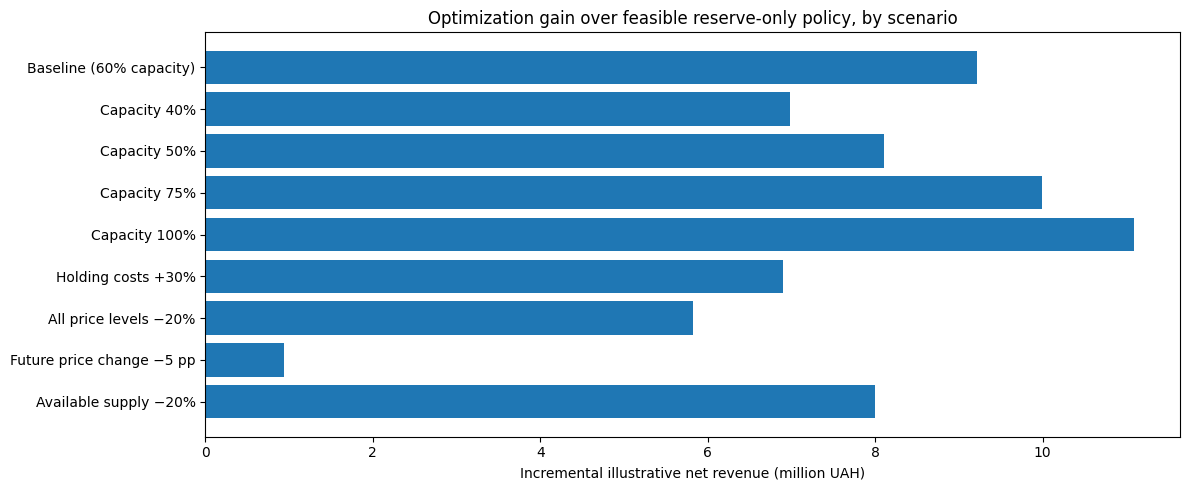

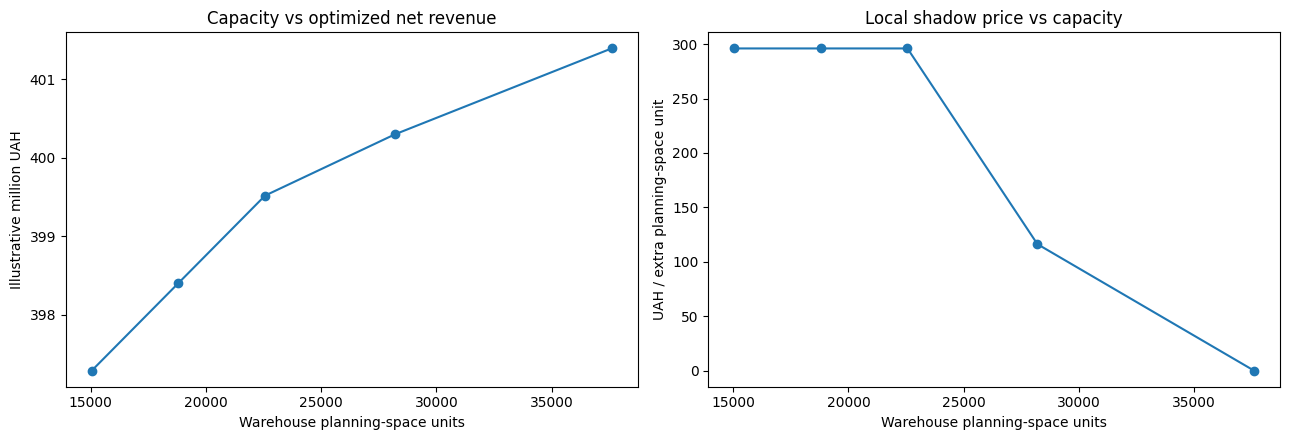

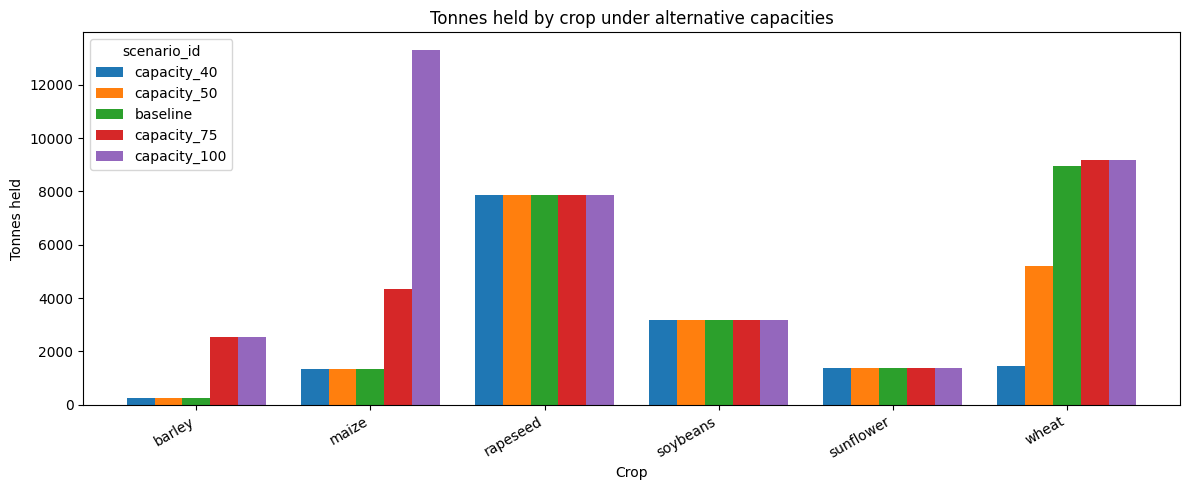

In [6]:
plt.style.use("default")
feasible=summary.loc[summary.status.eq("optimal")].copy()

fig,ax=plt.subplots(figsize=(12,5))
ax.barh(feasible["scenario"][::-1], (feasible["incremental_vs_reserve_only_uah"]/1e6)[::-1])
ax.set(title="Optimization gain over feasible reserve-only policy, by scenario",xlabel="Incremental illustrative net revenue (million UAH)")
plt.tight_layout();fig.savefig(OUT/"01_gain_over_reserve_only.png",dpi=150,bbox_inches="tight");plt.show()

capacity_cases=feasible[feasible.scenario_id.isin(["capacity_40","capacity_50","baseline","capacity_75","capacity_100"])].sort_values("capacity_space_units")
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].plot(capacity_cases.capacity_space_units,capacity_cases.objective_uah/1e6,marker="o")
axes[0].set(title="Capacity vs optimized net revenue",xlabel="Warehouse planning-space units",ylabel="Illustrative million UAH")
axes[1].plot(capacity_cases.capacity_space_units,capacity_cases.shadow_price_uah_per_space_unit,marker="o")
axes[1].set(title="Local shadow price vs capacity",xlabel="Warehouse planning-space units",ylabel="UAH / extra planning-space unit")
plt.tight_layout();fig.savefig(OUT/"02_capacity_sensitivity.png",dpi=150,bbox_inches="tight");plt.show()

pivot=all_allocations.pivot(index="crop",columns="scenario_id",values="hold_tonnes")
ordered=["capacity_40","capacity_50","baseline","capacity_75","capacity_100"]
ax=pivot[ordered].plot(kind="bar",figsize=(12,5),width=0.8)
ax.set(title="Tonnes held by crop under alternative capacities",xlabel="Crop",ylabel="Tonnes held")
plt.xticks(rotation=30,ha="right")
plt.tight_layout();ax.figure.savefig(OUT/"03_held_volume_by_capacity.png",dpi=150,bbox_inches="tight");plt.show()

## 5 · Explainability: which constraints and crops change?

Compare every optimal scenario with baseline. A lower bound means the crop is kept only to satisfy the minimum reserve; an upper bound means all available stock is held. A capacity shadow value greater than zero indicates that a *small* additional amount of storage would improve the model objective under unchanged assumptions.

In [7]:
delta = all_allocations.merge(
    baseline_detail[["crop","hold_tonnes","net_revenue_uah"]], on="crop",suffixes=("","_baseline")
)
delta["delta_hold_tonnes"] = delta.hold_tonnes - delta.hold_tonnes_baseline
delta["delta_crop_revenue_uah"] = delta.net_revenue_uah - delta.net_revenue_uah_baseline
display(delta.loc[delta.scenario_id.isin(["higher_holding_cost","lower_future_growth","capacity_40"]),
                  ["scenario","crop","hold_tonnes","delta_hold_tonnes","at_min_reserve","held_all"]].round(2))

bounds = all_allocations.groupby(["scenario_id","scenario"]).agg(
    crops_at_minimum=("at_min_reserve","sum"), crops_fully_held=("held_all","sum")
).reset_index()
explanation=feasible[["scenario_id","scenario","binding_capacity","shadow_price_uah_per_space_unit","utilization_pct"]].merge(bounds,on=["scenario_id","scenario"])
display(explanation.round(2))

,scenario,crop,hold_tonnes,delta_hold_tonnes,at_min_reserve,held_all
6,Capacity 40%,barley,252.46,0.00,True,False
7,Capacity 40%,maize,1329.72,0.00,True,False
8,Capacity 40%,rapeseed,7851.60,0.00,False,True
9,Capacity 40%,soybeans,3171.40,0.00,False,True
10,Capacity 40%,sunflower,1393.30,0.00,False,True
11,Capacity 40%,wheat,1438.12,-7520.42,False,False
30,Holding costs +30%,barley,252.46,0.00,True,False
31,Holding costs +30%,maize,1329.72,0.00,True,False
32,Holding costs +30%,rapeseed,7851.60,0.00,False,True
33,Holding costs +30%,soybeans,3171.40,0.00,False,True


,scenario_id,scenario,binding_capacity,shadow_price_uah_per_space_unit,utilization_pct,crops_at_minimum,crops_fully_held
0,baseline,Baseline (60% capacity),True,296.00,100.0,2,3
1,capacity_40,Capacity 40%,True,296.00,100.0,2,3
2,capacity_50,Capacity 50%,True,296.00,100.0,2,3
3,capacity_75,Capacity 75%,True,116.19,100.0,0,5
4,capacity_100,Capacity 100%,True,0.00,100.0,0,6
5,higher_holding_cost,Holding costs +30%,True,200.00,100.0,2,3
6,lower_current_prices,All price levels −20%,True,172.80,100.0,2,3
7,lower_future_growth,Future price change −5 pp,False,0.00,34.6,4,2
8,lower_supply,Available supply −20%,True,116.19,100.0,0,5


## 6 · Numerical and conceptual quality checks

In [8]:
assert summary.loc[summary.scenario_id.eq("too_small_capacity"),"status"].iloc[0] == "infeasible_reserve"
assert all_allocations["hold_tonnes"].ge(-1e-6).all()
assert (all_allocations["sell_now_tonnes"] >= -1e-6).all()
assert np.allclose(all_allocations.hold_tonnes+all_allocations.sell_now_tonnes,all_allocations.available_tonnes,atol=1e-5)
assert (feasible.used_space_units <= feasible.capacity_space_units+1e-5).all()
assert (feasible.objective_uah+1e-5 >= feasible.reserve_only_objective_uah).all()
assert (feasible.shadow_price_uah_per_space_unit >= -1e-5).all()
assert capacity_cases.objective_uah.is_monotonic_increasing
print("QA passed: baseline parity, stock conservation, LP feasibility, optimality vs reserve-only, capacity monotonicity, and deliberate infeasible case.")

QA passed: baseline parity, stock conservation, LP feasibility, optimality vs reserve-only, capacity monotonicity, and deliberate infeasible case.


## 7 · Export reproducible results and methodological notes

In [9]:
summary.to_csv(OUT/"scenario_summary.csv",index=False,encoding="utf-8-sig")
all_allocations.to_csv(OUT/"scenario_allocations.csv",index=False,encoding="utf-8-sig")
delta.to_csv(OUT/"scenario_vs_baseline_by_crop.csv",index=False,encoding="utf-8-sig")
explanation.to_csv(OUT/"scenario_explainability.csv",index=False,encoding="utf-8-sig")
with (OUT/"scenario_definitions.json").open("w",encoding="utf-8") as f:
    json.dump({"source_year":assumptions["source_year"],"illustrative":True,
               "base_capacity_share":BASE_CAPACITY_SHARE,"base_reserve_fraction":BASE_RESERVE,
               "scenario_capacity_reference_space_units":BASE_FULL_SPACE,
               "scenarios":SCENARIOS},f,indent=2,ensure_ascii=False)

baseline_row=summary.loc[summary.scenario_id.eq("baseline")].iloc[0]
cap40=summary.loc[summary.scenario_id.eq("capacity_40")].iloc[0]
cap100=summary.loc[summary.scenario_id.eq("capacity_100")].iloc[0]
notes=[
    "# Agricultural warehouse scenario simulation — findings",
    "",
    "**All prices, storage costs, reserves, capacity and future price changes are illustrative assumptions. Historical crop stocks are derived from 50-сг 2025 reports, not direct warehouse-capacity measurements.**",
    "",
    f"- Baseline optimized net revenue: {baseline_row.objective_uah:,.0f} UAH (reproduces notebook 04).",
    f"- Baseline gain vs **feasible reserve-only** alternative: {baseline_row.incremental_vs_reserve_only_uah:,.0f} UAH.",
    f"- Capacity 40% objective: {cap40.objective_uah:,.0f} UAH; capacity 100% objective: {cap100.objective_uah:,.0f} UAH.",
    "- Higher warehouse capacity cannot reduce the LP optimum with otherwise unchanged assumptions.",
    "- Shadow prices are local derivatives, not global gains over large capacity changes.",
    "- Insufficient capacity for mandatory crop reserves is explicitly flagged infeasible.",
    "- This is a single-period, deterministic allocation of sell-now versus hold-for-later quantities, NOT route optimization or real farm profit forecasting.",
]
(OUT/"scenario_findings.md").write_text("\n".join(notes)+"\n",encoding="utf-8")
print("Saved output files:")
for p in sorted(OUT.iterdir()):print(" ",p.name)

Saved output files:
  01_gain_over_reserve_only.png
  02_capacity_sensitivity.png
  03_held_volume_by_capacity.png
  scenario_allocations.csv
  scenario_definitions.json
  scenario_explainability.csv
  scenario_findings.md
  scenario_summary.csv
  scenario_vs_baseline_by_crop.csv
